# Дополнительный пример к главе 3. Аттрактор Лоренца: идентификация системы методом SINDy

**Учебное пособие «Нейронные сети для инженеров»** · сквозной пример «Аттрактор Лоренца», часть 1

---

**Задача.** По записи траектории $(x(t),y(t),z(t))$ динамической системы восстановить её уравнения. Метод SINDy (англ. Sparse Identification of Nonlinear Dynamics — разреженная идентификация нелинейной динамики) сводит эту задачу к линейному методу наименьших квадратов (МНК) в библиотеке заранее выбранных функций и добавляет требование **разреженности**: в уравнениях должно остаться как можно меньше членов.

**Почему это пример к главе 3.** SINDy — прямое применение формул главы:

| Идея главы 3 | Где она в этом примере |
|---|---|
| Линейная комбинация базисных функций (3.5), задача МНК (3.6) | модель $\dot{\mathbf x}=\Theta(\mathbf x)\,\Xi$ и её решение |
| Обусловленность $\mathbf V$ и $\mathbf V^{\mathsf T}\mathbf V$, решение через QR/SVD | нормировка столбцов библиотеки, шаг 2 |
| Регуляризация (3.7) | гребневая регрессия против пороговой, шаг 3 |
| Локальная полиномиальная аппроксимация | производные фильтром Савицкого–Голея, шаг 4 |
| Квадратурные формулы, пример 3.1 (ультразвуковой расходомер) | интегральная постановка: формула Симпсона вместо производных, шаг 4 |
| Сеть с фиксированными базисными признаками (рис. 3.5) | SINDy — однослойная линейная сеть на признаках-мономах |
| Экстраполяция и обобщение (п. 3.1.1, 3.1.3) | хаос: точные коэффициенты, но конечный горизонт прогноза, шаги 6–7 |

**Место в репозитории.** Это первая часть сквозного примера. Его продолжают:

- **глава 4** (`KAN_Lorenz_attarctor.ipynb`) — та же задача с сетью Колмогорова–Арнольда, у которой одномерные функции обучаются, а не задаются библиотекой. Там же разбирается вопрос, каких данных хватает гибкой модели;
- **глава 11** (планируется) — обратная задача для PINN: оценка $\sigma,\rho,\beta$ по редким зашумлённым наблюдениям.

**Блокнот полностью самостоятелен.** Он не читает и не записывает файлов: все функции определены в нём самом, данные моделируются при каждом запуске, рисунки и таблицы выводятся только на экран. Блокноты других глав устроены так же. Сопоставимость результатов между главами обеспечивают одинаковые параметры системы, начальные условия, шаг дискретизации и сиды генераторов, которые явно заданы в каждом блокноте (раздел «Подготовка вычислений»).

## 0. Обозначения

| Символ | Смысл |
|---|---|
| $t$ | время; $\Delta t=0{,}01$ — шаг записи наблюдений |
| $\mathbf x=(x,y,z)^{\mathsf T}$ | вектор состояния системы; $\dot{\mathbf x}=d\mathbf x/dt$ — его производная по времени |
| $\sigma,\ \rho,\ \beta$ | параметры системы Лоренца: число Прандтля, приведённое число Рэлея и геометрический множитель; классические значения $10$, $28$, $8/3$ |
| $N$ | число отсчётов траектории; $\mathbf X$ ($N\times3$) — матрица состояний, строка — одно наблюдение |
| $\Theta(\mathbf X)$ | библиотека признаков: матрица $N\times F$ значений $F$ мономов от $x,y,z$ степени не выше $d$ |
| $d,\ F$ | наибольшая степень мономов и число признаков: $F=10$ при $d=2$, $F=20$ при $d=3$ |
| $\Xi$ | матрица коэффициентов $F\times3$; столбец $i$ задаёт правую часть $i$-го уравнения; $\Xi^{*}$ — эталон |
| $\xi_{ki}$ | элемент $\Xi$: коэффициент $k$-го признака в $i$-м уравнении |
| $s_k$ | среднеквадратичное значение $k$-го столбца $\Theta$ (нормировка) |
| $\lambda_{\mathrm r}$ | параметр гребневой регрессии (в формуле 3.7 — $\lambda$; индекс добавлен, чтобы не путать с показателем Ляпунова) |
| $\tau$ | порог разреженности: относительный вклад члена, ниже которого он обнуляется |
| $\eta$ | относительный уровень шума измерений: СКО помехи равно $\eta$, умноженному на СКО координаты |
| $h,\ p$ | полуширина окна (в отсчётах) и степень локального полинома фильтра Савицкого–Голея |
| $m$ | длина окна интегрирования (в шагах $\Delta t$) в интегральной постановке |
| $\lambda_{\max}$ | старший показатель Ляпунова; $1/\lambda_{\max}$ — время Ляпунова |
| $D$ | масштаб аттрактора: среднеквадратичное расстояние точек траектории от её центра |
| $T_{\mathrm v}$ | время достоверного прогноза: момент, когда ошибка траектории превышает $0{,}4D$ |
| $\varepsilon_\Xi$ | относительная ошибка коэффициентов $\lVert\Xi-\Xi^{*}\rVert_F/\lVert\Xi^{*}\rVert_F$ ($\lVert\cdot\rVert_F$ — норма Фробениуса, корень из суммы квадратов элементов) |

In [1]:
import time
from itertools import combinations_with_replacement
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

%config InlineBackend.figure_formats = ['svg']
mpl.rcParams.update({
    "font.family": "STIXGeneral", "mathtext.fontset": "stix", "font.size": 11,
    "axes.titlesize": 11, "axes.labelsize": 11, "legend.fontsize": 9.5,
    "legend.frameon": False, "axes.prop_cycle": mpl.cycler(color=["black", "0.35", "0.6"]),
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": "0.85", "grid.linestyle": ":", "grid.linewidth": 0.7,
    "lines.linewidth": 1.3, "image.cmap": "gray", "figure.dpi": 110,
})

class CommaFormatter(mpl.ticker.ScalarFormatter):
    # Десятичная запятая на осях, как принято в русских текстах.
    def __call__(self, v, pos=None):
        return super().__call__(v, pos).replace(".", ",")

def commas(fig):
    for a in fig.axes:
        if getattr(a, "name", "") == "3d":
            continue
        if a.get_xscale() == "linear": a.xaxis.set_major_formatter(CommaFormatter())
        if a.get_yscale() == "linear": a.yaxis.set_major_formatter(CommaFormatter())

def rel_err(Xi, Xi0):  return np.linalg.norm(Xi - Xi0) / np.linalg.norm(Xi0)
def same_support(Xi, Xi0): return bool(np.array_equal(Xi != 0, Xi0 != 0))
np.set_printoptions(precision=5, suppress=True)
print("NumPy", np.__version__, "| pandas", pd.__version__, "| Matplotlib", mpl.__version__)

NumPy 2.2.5 | pandas 2.3.3 | Matplotlib 3.10.9


### Параметры эксперимента

Эти значения одинаковы во всех блокнотах сквозного примера: классические параметры Лоренца, шаг записи $\Delta t=0{,}01$, отбрасываемый переходный участок, начальные условия трёх записей и сиды генераторов шума. Изменив их здесь, вы меняете только этот блокнот.

In [2]:
SIGMA, RHO, BETA = 10.0, 28.0, 8.0 / 3.0   # классические параметры Лоренца
DT = 0.01                                   # шаг дискретизации наблюдений
T_TRANSIENT = 10.0                          # отбрасываемый переходный участок
LYAP = 0.9056                               # старший показатель Ляпунова (литературное значение)
SEED = 20261017                             # сид данных
NOISE_SEED = 314159                         # сид шума измерений
X0 = {"train": (-8.0, 7.0, 27.0), "val": (1.0, 1.0, 1.0), "test": (5.0, -5.0, 20.0)}
T_LEN = {"train": 50.0, "val": 20.0, "test": 30.0}
BOX = np.array([[-20.0, 20.0], [-25.0, 25.0], [0.0, 50.0]])   # область для box_points
VARS = ("x", "y", "z")

### Моделирование системы

Правые части (Л.1) и метод Рунге–Кутты 4-го порядка. Функции работают и с одной траекторией (массив $3$), и сразу с пакетом из $K$ траекторий (массив $K\times3$). Если траектория найденной модели «уходит на бесконечность», она помечается как `nan`, а остальные траектории пакета считаются дальше.

In [3]:
def lorenz_rhs(X, sigma=SIGMA, rho=RHO, beta=BETA):
    # Правые части системы Лоренца; X: (..., 3).
    x, y, z = X[..., 0], X[..., 1], X[..., 2]
    return np.stack([sigma * (y - x), x * (rho - z) - y, x * y - beta * z], axis=-1)


def rk4(f, x0, dt, n_steps):
    # Метод Рунге–Кутты 4-го порядка. x0: (3,) или (K, 3). Возвращает (n_steps+1, ..., 3).
    X = np.empty((n_steps + 1,) + np.shape(x0))
    X[0] = x0
    with np.errstate(all="ignore"):
        for k in range(n_steps):
            s = X[k]
            k1 = f(s); k2 = f(s + 0.5 * dt * k1); k3 = f(s + 0.5 * dt * k2); k4 = f(s + dt * k3)
            X[k + 1] = s + dt / 6.0 * (k1 + 2 * k2 + 2 * k3 + k4)
            bad = ~np.all(np.isfinite(X[k + 1]) & (np.abs(X[k + 1]) < 1e6), axis=-1)
            if np.any(bad):                            # траектория модели «ушла на бесконечность»
                X[k + 1][bad] = np.nan                 # остальные траектории считаются дальше
                if np.all(bad):
                    X[k + 1:] = np.nan
                    break
    return X


def simulate(x0, t_len, dt=DT, transient=T_TRANSIENT, f=lorenz_rhs, substeps=10):
    # Траектория с отброшенным переходным участком.
    # Интегрирование идёт с шагом dt/substeps, наблюдения сохраняются с шагом dt.
    h = dt / substeps
    n_tr = int(round(transient / h))
    if n_tr:
        x0 = rk4(f, np.asarray(x0, float), h, n_tr)[-1]
    n = int(round(t_len / dt))
    X = rk4(f, x0, h, n * substeps)[::substeps]
    return np.arange(n + 1) * dt, X


def make_record(name):
    # Траектория в памяти: (t, X, dX_true). Точные производные — только для контроля.
    t, X = simulate(X0[name], T_LEN[name])
    return t, X, lorenz_rhs(X)


def box_points(n, seed=SEED + 2):
    # Точки, равномерно покрывающие область BOX, и точные скорости в них (набор B главы 4).
    rng = np.random.default_rng(seed)
    X = BOX[:, 0] + (BOX[:, 1] - BOX[:, 0]) * rng.uniform(size=(n, 3))
    return X, lorenz_rhs(X)


def add_noise(X, eta, seed=NOISE_SEED):
    # Аддитивный гауссов шум с СКО eta * std(X_i) по каждой координате.
    rng = np.random.default_rng(seed)
    return X + eta * X.std(axis=0) * rng.standard_normal(X.shape)

### Производные, квадратуры, библиотека и SINDy

Здесь собраны все вычислительные приёмы, которые разбираются в шагах 2–4: центральные разности, фильтр Савицкого–Голея как локальный МНК, интегральная (квадратурная) постановка, полиномиальная библиотека и последовательная пороговая регрессия.

In [4]:
def central_diff(X, dt=DT):
    # Центральные разности второго порядка; возвращает (X[1:-1], dX).
    return X[1:-1], (X[2:] - X[:-2]) / (2 * dt)


def savgol_weights(half, order, dt=DT):
    # Веса фильтра Савицкого–Голея: локальный МНК-полином степени order
    # на окне из 2*half+1 точек. Возвращает веса значения и первой производной в центре.
    s = np.arange(-half, half + 1) * dt
    V = np.vander(s, order + 1, increasing=True)        # базис 1, s, s^2, ...
    Pinv = np.linalg.pinv(V)                             # коэффициенты полинома = Pinv @ y
    return Pinv[0], Pinv[1]                              # c0 = значение, c1 = производная


def savgol_diff(X, half=7, order=3, dt=DT):
    # Сглаженные состояния и производные; края (по half точек) отбрасываются.
    w0, w1 = savgol_weights(half, order, dt)
    n = X.shape[0] - 2 * half
    idx = np.arange(n)[:, None] + np.arange(2 * half + 1)[None, :]
    win = X[idx]                                         # (n, 2h+1, 3)
    return np.einsum("k,nkd->nd", w0, win), np.einsum("k,nkd->nd", w1, win)


def window_integrals(Theta, X, m, rule="simpson", dt=DT):
    # Интегральная (квадратурная) постановка SINDy: x(t_k+m) - x(t_k) = ∫ Θ(x) dt · Ξ.
    # Интеграл по окну из m шагов вычисляется квадратурой (trapezoid или simpson, m чётное).
    # Возвращает (интегралы признаков, приращения состояния) по перекрывающимся окнам.
    if rule == "trapezoid":
        w = np.ones(m + 1); w[[0, -1]] = 0.5; w *= dt
    elif rule == "simpson":
        assert m % 2 == 0, "для формулы Симпсона число шагов m должно быть чётным"
        w = np.ones(m + 1); w[1:-1:2] = 4; w[2:-1:2] = 2; w *= dt / 3
    else:
        raise ValueError(rule)
    win = np.lib.stride_tricks.sliding_window_view(Theta, m + 1, axis=0)   # (N-m, F, m+1)
    return win @ w, X[m:] - X[:-m]


def library(X, degree=3):
    # Мономы от x, y, z до степени degree. Возвращает (Θ, имена в LaTeX, показатели).
    exps = []
    for d in range(degree + 1):
        for comb in combinations_with_replacement(range(3), d):
            e = [0, 0, 0]
            for c in comb:
                e[c] += 1
            exps.append(tuple(e))
    names = []
    for e in exps:
        s = "".join(v + (f"^{p}" if p > 1 else "") for v, p in zip(VARS, e) if p)
        names.append(s if s else "1")
    E = np.array(exps)
    Theta = np.prod(X[:, None, :] ** E[None, :, :], axis=2)
    return Theta, names, E


def ridge_lstsq(A, b, lam, free=(0,)):
    # min ||A c - b||^2 + lam * sum_{k not in free} c_k^2  (формула 3.7).
    if lam == 0:
        return np.linalg.lstsq(A, b, rcond=None)[0]
    D = np.sqrt(lam) * np.eye(A.shape[1])
    for k in free:
        D[k, k] = 0.0
    return np.linalg.lstsq(np.vstack([A, D]), np.vstack([b, np.zeros((A.shape[1], b.shape[1]))]),
                           rcond=None)[0]


def stlsq(Theta, dX, threshold, ridge=0.0, max_iter=25):
    # Последовательная пороговая регрессия (STLSQ, алгоритм SINDy).
    # Столбцы Θ нормируются на свои среднеквадратичные значения s_k; член с относительным
    # вкладом |ξ_k|·s_k / s(ẋ_i) < threshold обнуляется, остальные пересчитываются МНК.
    # Возвращает Ξ в исходных единицах (n_features x 3).
    s = np.sqrt(np.mean(Theta ** 2, axis=0)); s[s == 0] = 1.0   # среднеквадратичные нормы столбцов
    A = Theta / s
    sy = np.sqrt(np.mean(dX ** 2, axis=0))
    Xi = ridge_lstsq(A, dX, ridge)
    active = np.ones_like(Xi, bool)
    for _ in range(max_iter):
        new = np.abs(Xi) / sy >= threshold
        if np.array_equal(new, active):
            break
        active = new
        for i in range(dX.shape[1]):
            Xi[:, i] = 0.0
            if active[:, i].any():
                Xi[active[:, i], i] = ridge_lstsq(A[:, active[:, i]], dX[:, [i]], ridge, free=())[:, 0]
    return Xi / s[:, None]


def true_coefficients(names, sigma=SIGMA, rho=RHO, beta=BETA):
    Xi = np.zeros((len(names), 3))
    ref = {("x", 0): -sigma, ("y", 0): sigma, ("x", 1): rho, ("y", 1): -1.0, ("xz", 1): -1.0,
           ("xy", 2): 1.0, ("z", 2): -beta}
    for (n, i), v in ref.items():
        Xi[names.index(n), i] = v
    return Xi


def model_rhs(Xi, degree=3):
    # Правая часть ẋ = Θ(x) Ξ для интегрирования найденной модели.
    _, _, E = library(np.zeros((1, 3)), degree)
    def f(S):
        S2 = np.atleast_2d(S)
        Th = np.prod(S2[:, None, :] ** E[None, :, :], axis=2)
        return (Th @ Xi).reshape(np.shape(S))
    return f

### Метрики для хаотической системы

Старший показатель Ляпунова (метод Бенеттина), масштаб аттрактора $D$, время достоверного прогноза $T_{\mathrm v}$ и отображение Лоренца — они используются в шагах 1, 6 и 7.

In [5]:
def lyapunov_max(f=lorenz_rhs, x0=X0["train"], dt=0.005, t_len=200.0, d0=1e-8, renorm=0.1):
    # Старший показатель Ляпунова методом Бенеттина: две близкие траектории,
    # перенормировка расстояния через каждые renorm единиц времени.
    _, x = simulate(x0, 0.0, dt=dt, substeps=1)
    a = x[-1]; b = a + np.array([d0, 0, 0])
    m = int(round(renorm / dt)); s = 0.0; n = int(round(t_len / renorm))
    for _ in range(n):
        a = rk4(f, a, dt, m)[-1]; b = rk4(f, b, dt, m)[-1]
        d = np.linalg.norm(b - a); s += np.log(d / d0)
        b = a + (b - a) * d0 / d
    return s / (n * renorm)


def attractor_scale(X):
    # Масштаб аттрактора D = sqrt(<||x - <x>||^2>).
    return np.sqrt(np.mean(np.sum((X - X.mean(axis=0)) ** 2, axis=1)))


def valid_time(X_true, X_pred, t, D, tol=0.4):
    # Время достоверного прогноза: первый момент, когда ||x̂ - x|| / D > tol.
    e = np.linalg.norm(X_pred - X_true, axis=1) / D
    bad = np.flatnonzero(~(e <= tol))
    return t[bad[0]] if bad.size else t[-1]


def lorenz_map(z):
    # Последовательные локальные максимумы z: пары (z_n, z_{n+1}).
    i = np.flatnonzero((z[1:-1] > z[:-2]) & (z[1:-1] >= z[2:])) + 1
    zm = z[i]
    return zm[:-1], zm[1:]

## Шаг 1. Система Лоренца и общие данные

Система Лоренца (1963) — упрощённая модель конвекции в слое жидкости, подогреваемом снизу:
$$
\dot x=\sigma(y-x),\qquad \dot y=x(\rho-z)-y,\qquad \dot z=xy-\beta z. \tag{Л.1}
$$
Здесь $x$ пропорционально скорости конвективного движения, $y$ и $z$ — отклонениям температуры от равновесного профиля по горизонтали и вертикали. Та же система описывает одномодовый лазер, водяное колесо Малкуса и электронные схемы-генераторы хаоса. Последний вариант делает пример инженерным: такую схему можно собрать на операционных усилителях и аналоговых умножителях, записать её напряжения и проверить, восстанавливаются ли уравнения.

Траектории получены методом Рунге–Кутты 4-го порядка с внутренним шагом $\Delta t/10$; переходный участок длиной 10 единиц времени отброшен. Моделируются три записи: обучающая (50 единиц времени, $N=5001$), валидационная (20) и тестовая (30), начатые из разных точек. Точные производные вычисляются только для **контроля**: при идентификации используются лишь сами состояния.

Моделирование: 8.8 с
Обучение: N = 5001, валидация: 2001, тест: 3001
СКО координат: [7.73427 8.86978 8.64818];  масштаб аттрактора D = 14.604
Старший показатель Ляпунова (Бенеттин, 200 ед. времени): 0.8962  (литература: 0.9056);  время Ляпунова ≈ 1.10


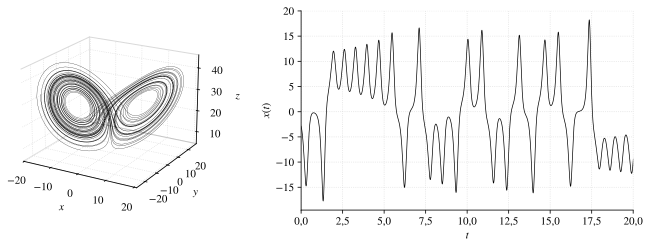

In [6]:
t0 = time.perf_counter()
t_tr, X_tr, dX_tr = make_record("train")
t_va, X_va, dX_va = make_record("val")
t_te, X_te, dX_te = make_record("test")
print(f"Моделирование: {time.perf_counter()-t0:.1f} с")
D = attractor_scale(X_tr)
print(f"Обучение: N = {X_tr.shape[0]}, валидация: {X_va.shape[0]}, тест: {X_te.shape[0]}")
print(f"СКО координат: {X_tr.std(0)};  масштаб аттрактора D = {D:.3f}")

t0 = time.perf_counter(); lam_est = lyapunov_max(); t_lyap = time.perf_counter() - t0
print(f"Старший показатель Ляпунова (Бенеттин, 200 ед. времени): {lam_est:.4f}  "
      f"(литература: {LYAP});  время Ляпунова ≈ {1/LYAP:.2f}")

fig = plt.figure(figsize=(10, 3.6))
ax = fig.add_subplot(1, 2, 1, projection="3d")
ax.plot(*X_tr.T, color="black", lw=0.25)
ax.set_xlabel("$x$"); ax.set_ylabel("$y$"); ax.set_zlabel("$z$")
for p in (ax.xaxis, ax.yaxis, ax.zaxis):
    p.pane.set_facecolor("white"); p.pane.set_edgecolor("0.7")
ax.view_init(20, -60)
ax2 = fig.add_subplot(1, 2, 2)
ax2.plot(t_tr, X_tr[:, 0], "k-", lw=0.7)
ax2.set_xlim(0, 20); ax2.set_xlabel("$t$"); ax2.set_ylabel("$x(t)$")
fig.tight_layout(); commas(fig); plt.show()

*Рис. Л1.* Аттрактор Лоренца (обучающая запись) и фрагмент временного ряда $x(t)$. Переключения между «крыльями» нерегулярны: это хаос, а не шум. Система детерминирована, но малые различия начальных состояний растут как $e^{\lambda_{\max}t}$.

**Показатель Ляпунова** $\lambda_{\max}\approx0{,}906$ задаёт естественную единицу времени задачи, время Ляпунова $1/\lambda_{\max}\approx1{,}1$. За это время малая ошибка вырастает в $e$ раз. В шагах 6–7 горизонт прогноза измеряется именно в этих единицах.

## Шаг 2. SINDy как метод наименьших квадратов в библиотеке функций

Если производные $\dot{\mathbf X}$ известны, каждое уравнение (Л.1) — линейная комбинация мономов от $x,y,z$. Составим библиотеку $\Theta(\mathbf X)$ из всех мономов степени не выше $d$ и запишем модель
$$
\dot{\mathbf X}\approx\Theta(\mathbf X)\,\Xi. \tag{Л.2}
$$
Это формула (3.5), применённая сразу к трём выходам: модель **линейна по коэффициентам** $\Xi$ и нелинейна по состоянию. При $d=3$ библиотека содержит $F=20$ мономов, то есть 60 коэффициентов, из которых в истинной системе ненулевых только 7.

In [7]:
Th_tr, names, E = library(X_tr, 3)
Xi_true = true_coefficients(names)
show = pd.DataFrame(Xi_true, index=[f"${n}$" for n in names], columns=["$\\dot x$", "$\\dot y$", "$\\dot z$"])
display(show[(show != 0).any(axis=1)].round(4))

s = np.sqrt(np.mean(Th_tr**2, axis=0))
print(f"Признаков F = {len(names)}, ненулевых коэффициентов в эталоне: {(Xi_true != 0).sum()} из {Xi_true.size}")
print(f"Диапазон норм столбцов s_k: от {s.min():.3g} до {s.max():.3g}")
print(f"cond(Θ) = {np.linalg.cond(Th_tr):.3g};  cond(Θ с нормированными столбцами) = {np.linalg.cond(Th_tr/s):.3g}")

# Точные производные: обычный МНК восстанавливает уравнения до округления
Xi_exact = np.linalg.lstsq(Th_tr, dX_tr, rcond=None)[0]
print(f"МНК по точным производным: ε_Ξ = {rel_err(Xi_exact, Xi_true):.2e}, "
      f"max |ξ| у ложных членов = {np.abs(Xi_exact[Xi_true == 0]).max():.1e}")

,$\dot x$,$\dot y$,$\dot z$
$x$,-10.0,28.0,0.0000
$y$,10.0,-1.0,0.0000
$z$,0.0,0.0,-2.6667
$xy$,0.0,0.0,1.0000
$xz$,0.0,-1.0,0.0000


Признаков F = 20, ненулевых коэффициентов в эталоне: 7 из 60
Диапазон норм столбцов s_k: от 1 до 2.55e+04
cond(Θ) = 7.17e+05;  cond(Θ с нормированными столбцами) = 1.25e+03
МНК по точным производным: ε_Ξ = 5.07e-12, max |ξ| у ложных членов = 1.5e-10


**Нормировка столбцов.** Мономы третьей степени принимают значения порядка $10^4$, а константа равна 1. Разброс масштабов делает матрицу $\Theta$ плохо обусловленной. Деление столбцов на их среднеквадратичные значения $s_k$ уменьшает число обусловленности на несколько порядков; задача МНК при этом не меняется, меняются лишь единицы коэффициентов. Это та же забота о точности вычислений, что и отказ от нормальных уравнений в п. 3.2.1.

С точными производными обычный МНК восстанавливает уравнения практически точно: модель (Л.2) содержит истинную систему, данных много, шума нет. Вся трудность реальной задачи — в том, что производные **не измеряются**.

## Шаг 3. Разреженность: МНК, гребневая регрессия и пороговое отсечение

Оценим производные центральными разностями $\dot{\mathbf x}(t_k)\approx[\mathbf x(t_{k+1})-\mathbf x(t_{k-1})]/(2\Delta t)$ по **чистым** данным. Даже без шума у этой оценки есть ошибка порядка $\Delta t^2\,\dddot{\mathbf x}/6$. Посмотрим, как на неё реагируют три способа определения $\Xi$:

1. **МНК (3.6)** — подгоняет все 60 коэффициентов, ложные члены получают малые ненулевые значения;
2. **гребневая регрессия (3.7)** — штраф $\lambda_{\mathrm r}\sum\xi_k^2$ уменьшает коэффициенты, но **не обнуляет** их;
3. **последовательная пороговая регрессия** (англ. sequentially thresholded least squares, STLSQ) — после МНК члены с относительным вкладом
$$
\frac{|\xi_{ki}|\,s_k}{\lVert\dot{\mathbf x}_i\rVert_{\mathrm{rms}}}<\tau
$$
обнуляются, а оставшиеся пересчитываются МНК; шаги повторяются, пока набор членов не перестанет меняться. Здесь $\lVert\dot{\mathbf x}_i\rVert_{\mathrm{rms}}$ — среднеквадратичное значение производной $i$-й координаты.

In [8]:
Xc, dXc = central_diff(X_tr)
Thc = library(Xc, 3)[0]
sc = np.sqrt(np.mean(Thc**2, axis=0))
Xi_ls = np.linalg.lstsq(Thc, dXc, rcond=None)[0]
Xi_rg = ridge_lstsq(Thc / sc, dXc, 1.0) / sc[:, None]
Xi_st = stlsq(Thc, dXc, 0.05)

tab = pd.DataFrame([{"метод": n, "ненулевых": int((np.abs(X) > 1e-12).sum()), "ε_Ξ": rel_err(X, Xi_true),
                     "структура верна": same_support(np.where(np.abs(X) > 1e-12, X, 0), Xi_true)}
                    for n, X in [("МНК (3.6)", Xi_ls), ("гребневая (3.7), λr = 1", Xi_rg), ("STLSQ, τ = 0,05", Xi_st)]])
display(tab.set_index("метод").style.format({"ε_Ξ": "{:.2e}"}))

# Относительный вклад истинных членов — обоснование выбора τ
contrib = np.abs(Xi_true) * sc[:, None] / np.sqrt(np.mean(dXc**2, axis=0))
rows = [{"уравнение": ["dx/dt", "dy/dt", "dz/dt"][i], "член": f"${names[k]}$", "вклад": contrib[k, i]}
        for k, i in zip(*np.nonzero(Xi_true))]
display(pd.DataFrame(rows).sort_values("вклад").style.format({"вклад": "{:.3f}"}).hide(axis="index"))

,ненулевых,ε_Ξ,структура верна
метод,,,
МНК (3.6),60,1.92e-02,False
"гребневая (3.7), λr = 1",60,5.28e-01,False
"STLSQ, τ = 0,05",7,6.47e-03,True


уравнение,член,вклад
dy/dt,$y$,0.138
dz/dt,$z$,0.843
dz/dt,$xy$,1.313
dx/dt,$x$,1.849
dx/dt,$y$,2.109
dy/dt,$x$,3.391
dy/dt,$xz$,3.751


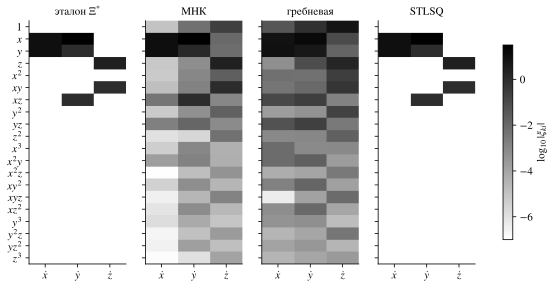

In [9]:
fig, ax = plt.subplots(1, 4, figsize=(10, 4.4), sharey=True)
eps = 1e-7
for a, (ttl, X) in zip(ax, [("эталон $\\Xi^{*}$", Xi_true), ("МНК", Xi_ls),
                           ("гребневая", Xi_rg), ("STLSQ", Xi_st)]):
    im = a.imshow(np.log10(np.abs(X) + eps), cmap="gray_r", vmin=-7, vmax=1.5, aspect="auto")
    a.set_xticks(range(3)); a.set_xticklabels(["$\\dot x$", "$\\dot y$", "$\\dot z$"])
    a.set_title(ttl); a.grid(False)
ax[0].set_yticks(range(len(names))); ax[0].set_yticklabels([f"${n}$" for n in names])
cb = fig.colorbar(im, ax=ax, shrink=0.8); cb.set_label("$\\log_{10}|\\xi_{ki}|$")
plt.show()

*Рис. Л2.* Модули коэффициентов (логарифмическая шкала; белый — нуль). МНК и гребневая регрессия «размазывают» ошибку разностной производной по всем 60 коэффициентам; STLSQ оставляет ровно семь членов истинной системы.

**Выбор порога.** Самый слабый истинный член — $-y$ в уравнении для $\dot y$: его относительный вклад около $0{,}1$. Порог $\tau$ должен быть заметно меньше, иначе он отрежет физику; и заметно больше вклада ложных членов, иначе они останутся. Значение $\tau=0{,}05$ лежит между ними. Порог — гиперпараметр, и выбирать его надо по **валидационным** данным, как сложность модели в п. 3.1.3. Покажем это на зашумлённой записи ($\eta=1\%$) с производными, вычисленными фильтром из шага 4.

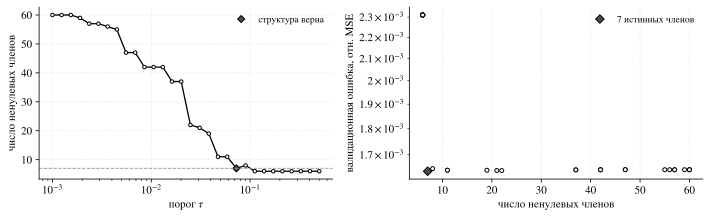

In [10]:
def prep_sg(X, eta, seed, half=7, order=5):
    Xs, d = savgol_diff(add_noise(X, eta, seed), half, order)
    return library(Xs, 3)[0], d

Th1, d1 = prep_sg(X_tr, 0.01, NOISE_SEED)
Th1v, d1v = prep_sg(X_va, 0.01, NOISE_SEED + 1)
taus = np.logspace(-3, np.log10(0.5), 30)
pareto = []
for tau in taus:
    Xi = stlsq(Th1, d1, tau)
    val = np.mean(np.mean((Th1v @ Xi - d1v)**2, axis=0) / np.mean(d1v**2, axis=0))
    pareto.append((tau, int((Xi != 0).sum()), val, same_support(Xi, Xi_true)))
pareto = np.array(pareto, dtype=object)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
k, v, ok = pareto[:, 1].astype(int), pareto[:, 2].astype(float), pareto[:, 3].astype(bool)
ax[0].semilogx(taus, k, "k-o", ms=3.5, mfc="white")
ax[0].semilogx(taus[ok], k[ok], "D", ms=5, mfc="0.3", mec="black", label="структура верна")
ax[0].axhline(7, color="0.6", ls="--", lw=0.9); ax[0].set_xlabel("порог $\\tau$")
ax[0].set_ylabel("число ненулевых членов"); ax[0].legend()
ax[1].semilogy(k, v, "ko", ms=4, mfc="white")
ax[1].semilogy(k[ok], v[ok], "D", ms=6, mfc="0.3", mec="black", label="7 истинных членов")
ax[1].set_xlabel("число ненулевых членов"); ax[1].set_ylabel("валидационная ошибка, отн. MSE")
ax[1].legend(); fig.tight_layout(); commas(fig); plt.show()

*Рис. Л3.* Выбор порога при шуме $\eta=1\%$: число оставшихся членов (слева) и компромисс «сложность — валидационная ошибка» (справа, фронт Парето).

При малых $\tau$ в модели остаются десятки членов, и валидационная ошибка почти не меньше, чем у модели из семи членов: лишние члены описывают шум обучающей записи, а не систему. При слишком больших $\tau$ ошибка растёт — отрезан истинный член $-y$. «Колено» кривой указывает на простейшую модель, после которой усложнение почти не помогает. Это принцип экономности, который в главе 6 станет регуляризацией по числу параметров.

## Шаг 4. Производные по данным: разности, локальный МНК, квадратуры

### 4а. Почему дифференцирование усиливает шум

Если отсчёты содержат независимую помеху с СКО $\eta\,s_x$ ($s_x$ — СКО координаты), то центральная разность имеет шумовую составляющую с СКО
$$
\frac{\sqrt2\,\eta\,s_x}{2\Delta t}=\frac{\eta\,s_x}{\sqrt2\,\Delta t}\approx70\,\eta\,s_x\quad\text{при }\Delta t=0{,}01.
$$
Шум 1 % в координате превращается в шум порядка 70 % от масштаба $s_x$ в производной. Численное дифференцирование — классическая **некорректная задача** (глава 6): малое возмущение данных даёт большое возмущение результата.

### 4б. Фильтр Савицкого–Голея как локальный МНК

Фильтр Савицкого–Голея (1964) в каждой точке строит по МНК полином степени $p$ на окне из $2h+1$ соседних отсчётов и берёт производную этого полинома в центре. Это локальная полиномиальная аппроксимация п. 3.2.2, вычисленная один раз для всех окон: веса фильтра — строка псевдообратной матрицы Вандермонда. Ширина окна задаёт компромисс: шире окно — меньше шум, но больше систематическое искажение быстрых участков траектории.

η = 0.00: центральная разность, отн. ошибка производной = 0.0044
η = 0.01: центральная разность, отн. ошибка производной = 0.1015
η = 0.03: центральная разность, отн. ошибка производной = 0.3042


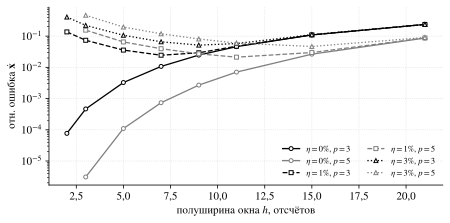

In [11]:
halves = [2, 3, 5, 7, 9, 11, 15, 21]
fig, ax = plt.subplots(figsize=(6.4, 3.3))
for eta, ls, mk in [(0.0, "-", "o"), (0.01, "--", "s"), (0.03, ":", "^")]:
    Xn = add_noise(X_tr, eta)
    for order, col in [(3, "black"), (5, "0.5")]:
        err = []
        for h in halves:
            if 2*h + 1 <= order + 1: err.append(np.nan); continue
            _, d = savgol_diff(Xn, h, order)
            ref = dX_tr[h:-h]
            err.append(np.mean(np.sqrt(np.mean((d - ref)**2, axis=0)) / ref.std(axis=0)))
        ax.semilogy(halves, err, color=col, ls=ls, marker=mk, ms=4, mfc="white",
                    label=f"$\\eta={eta*100:g}\\%$, $p={order}$".replace(".", "{,}"))
    _, d = central_diff(Xn)
    print(f"η = {eta:4.2f}: центральная разность, отн. ошибка производной = "
          f"{np.mean(np.sqrt(np.mean((d - dX_tr[1:-1])**2, 0)) / dX_tr.std(0)):.4f}")
ax.set_xlabel("полуширина окна $h$, отсчётов"); ax.set_ylabel("отн. ошибка $\\dot{\\mathbf{x}}$")
ax.legend(ncol=2, fontsize=8.5); fig.tight_layout(); commas(fig); plt.show()

*Рис. Л4.* Ошибка оценки производной фильтром Савицкого–Голея в зависимости от ширины окна (относительно СКО истинной производной).

Без шума лучше всего узкое окно: ошибка определяется только искажением. С шумом у кривых появляется минимум; полином пятой степени допускает более широкое окно, чем кубический. Этот же компромисс «смещение — разброс» лежит в основе выбора сложности любой модели. Далее используем $h=7$, $p=5$.

### 4в. Интегральная постановка: квадратура вместо производной

Можно вообще не дифференцировать данные. Проинтегрируем (Л.2) по окну $[t_k,\,t_{k+m}]$:
$$
\mathbf x(t_{k+m})-\mathbf x(t_k)=\int_{t_k}^{t_{k+m}}\Theta(\mathbf x(t))\,dt\;\Xi. \tag{Л.3}
$$
Слева — приращение состояния без деления на $\Delta t$; справа — интегралы признаков, которые вычисляются квадратурной формулой (3.14) по отсчётам. Задача для $\Xi$ остаётся линейной. Сравним формулу трапеций и формулу Симпсона на чистых данных.

In [12]:
rows = []
for m in [10, 20, 40]:
    for rule, nm in [("trapezoid", "трапеций"), ("simpson", "Симпсона")]:
        A, b = window_integrals(Th_tr, X_tr, m, rule)
        Xi = stlsq(A, b, 0.05)
        rows.append({"окно m": m, "квадратура": nm, "ε_Ξ": rel_err(Xi, Xi_true), "структура верна": same_support(Xi, Xi_true)})
Xs, d = savgol_diff(X_tr, 7, 5); Xi_sg0 = stlsq(library(Xs, 3)[0], d, 0.05)
rows += [{"окно m": "—", "квадратура": "центр. разности (производная)", "ε_Ξ": rel_err(Xi_st, Xi_true), "структура верна": same_support(Xi_st, Xi_true)},
         {"окно m": "—", "квадратура": "Савицкий–Голей h=7, p=5", "ε_Ξ": rel_err(Xi_sg0, Xi_true), "структура верна": same_support(Xi_sg0, Xi_true)}]
display(pd.DataFrame(rows).set_index(["окно m", "квадратура"]).style.format({"ε_Ξ": "{:.2e}"}))

Формула Симпсона точнее формулы трапеций на три порядка: её степень точности выше, а траектория гладкая. Это ровно тот выбор, который в примере 3.1 решал судьбу ультразвукового расходомера, — только там квадратура переводила несколько акустических измерений в расход, а здесь переводит отсчёты траектории в уравнения движения.

> **Перекрёстная связь.** Интегральная постановка (Л.3) — частный случай «слабой» формы уравнений: вместо самого уравнения проверяется его интеграл с весом. Та же идея лежит в основе метода Галёркина и вариационных принципов (глава 5), а в главе 11 PINN проверяет уравнение в точках коллокации — это противоположный, «сильный» вариант той же проверки.

## Шаг 5. Шум измерений и размер библиотеки

Сравним три способа подготовки данных — центральные разности (ЦР), фильтр Савицкого–Голея (СГ) и интегральную постановку с формулой Симпсона ($m=10$) — для двух библиотек: $d=2$ (10 мономов; в ней лежит истинная система) и $d=3$ (20 мономов; лишняя свобода). Для каждого уровня шума $\eta$ берём 5 независимых реализаций помехи и считаем долю запусков, в которых структура уравнений восстановлена **точно** (те же 7 членов), и медианную ошибку коэффициентов. Порог $\tau=0{,}05$ фиксирован.

In [13]:
etas = [0.0, 0.0025, 0.005, 0.01, 0.02, 0.03, 0.05]
REPS = 5
methods = ["ЦР", "СГ", "Симпсон"]
res = []
t0 = time.perf_counter()
for deg in [2, 3]:
    names_d = library(X_tr[:1], deg)[1]; Xi0 = true_coefficients(names_d)
    for eta in etas:
        for r in range(REPS if eta > 0 else 1):
            Xn = add_noise(X_tr, eta, seed=NOISE_SEED + 100 + r)
            for meth in methods:
                if meth == "ЦР":
                    Xs, d = central_diff(Xn); A, b = library(Xs, deg)[0], d
                elif meth == "СГ":
                    Xs, d = savgol_diff(Xn, 7, 5); A, b = library(Xs, deg)[0], d
                else:
                    A, b = window_integrals(library(Xn, deg)[0], Xn, 10, "simpson")
                Xi = stlsq(A, b, 0.05)
                res.append(dict(d=deg, eta=eta, rep=r, метод=meth, err=rel_err(Xi, Xi0),
                                ok=same_support(Xi, Xi0), n=int((Xi != 0).sum())))
res = pd.DataFrame(res)
print(f"{len(res)} идентификаций за {time.perf_counter()-t0:.1f} с")
summary = res.groupby(["d", "метод", "eta"]).agg(доля_верных=("ok", "mean"), медиана_ε=("err", "median"),
                                                 медиана_членов=("n", "median")).reset_index()
display(summary.pivot_table(index="eta", columns=["d", "метод"], values="доля_верных").round(2))

186 идентификаций за 1.6 с


d         2                 3             
метод    СГ Симпсон   ЦР   СГ Симпсон   ЦР
eta                                       
0.0000  1.0     1.0  1.0  1.0     1.0  1.0
0.0025  1.0     1.0  1.0  1.0     1.0  1.0
0.0050  1.0     1.0  1.0  1.0     1.0  0.0
0.0100  1.0     1.0  1.0  0.2     0.4  0.0
0.0200  1.0     1.0  1.0  0.0     0.0  0.0
0.0300  1.0     1.0  0.0  0.0     0.0  0.0
0.0500  0.0     0.8  0.0  0.0     0.0  0.0

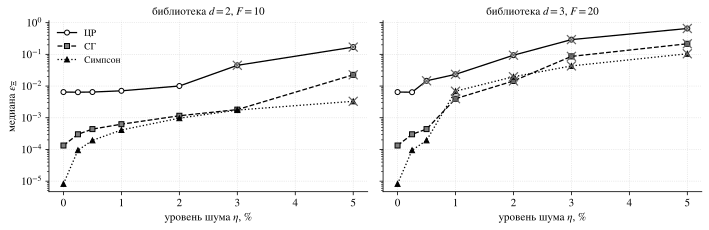

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
sty = {"ЦР": ("-", "o", "white"), "СГ": ("--", "s", "0.5"), "Симпсон": (":", "^", "black")}
for a, deg in zip(ax, [2, 3]):
    for meth in methods:
        q = summary[(summary.d == deg) & (summary["метод"] == meth)]
        ls, mk, fc = sty[meth]
        a.semilogy(q.eta * 100, q["медиана_ε"], color="black", ls=ls, marker=mk, mfc=fc, ms=5, label=meth)
        bad = q[q["доля_верных"] < 1]
        a.semilogy(bad.eta * 100, bad["медиана_ε"], "x", color="0.4", ms=9, mew=1.2)
    a.set_title(f"библиотека $d={deg}$, $F={10 if deg == 2 else 20}$")
    a.set_xlabel("уровень шума $\\eta$, %")
ax[0].set_ylabel("медиана $\\varepsilon_\\Xi$"); ax[0].legend()
fig.tight_layout(); commas(fig); plt.show()

*Рис. Л5.* Медианная ошибка коэффициентов в зависимости от уровня шума. Крестиком отмечены точки, где хотя бы в одной реализации структура уравнений восстановлена неверно.

**Выводы шага.**

1. **Способ получения производных важнее метода регрессии.** С библиотекой $d=3$ центральные разности теряют структуру уже при шуме 0,5 %. С библиотекой $d=2$ квадратурная постановка выдерживает шум до 3 % во всех реализациях и 5 % — в четырёх из пяти, тогда как центральные разности — лишь до 2 %.
2. **Размер библиотеки — это априорное знание.** С библиотекой $d=2$ система восстанавливается при шуме в несколько процентов; с библиотекой $d=3$ те же данные дают ложные члены уже при 1 %. Лишние 10 мономов — это лишняя свобода, которой модель распоряжается, подгоняя шум. Это переобучение в чистом виде (глава 6).
3. **Систематическая ошибка при шуме в признаках.** Помеха входит не только в $\dot{\mathbf x}$, но и в $\Theta(\mathbf X)$: например, среднее $(x+\varepsilon)^2$ больше $x^2$ на дисперсию помехи. Поэтому оценки при сильном шуме смещены даже при бесконечно длинной записи — это задача с ошибками в переменных, и МНК для неё не оптимален.

> **Перекрёстная связь с главой 4.** Пункт 2 — ключ к продолжению. Сеть Колмогорова–Арнольда устроена как предельно гибкая «библиотека»: она сама обучает одномерные функции. За гибкость приходится платить требованиями к данным, и в блокноте главы 4 это видно сразу.

## Шаг 6. Прогноз траектории найденной моделью

Найденные уравнения интегрируем из **начального состояния тестовой записи** и сравниваем с истинной траекторией. Время достоверного прогноза $T_{\mathrm v}$ — первый момент, когда расстояние между траекториями превышает $0{,}4D$; его удобно выражать в единицах времени Ляпунова $\lambda_{\max}T_{\mathrm v}$. Для одной стартовой точки $T_{\mathrm v}$ сильно зависит от того, где на аттракторе она лежит: вблизи «развилки» между крыльями ошибка растёт быстрее. Поэтому дополнительно усредняем $T_{\mathrm v}$ по 15 стартам вдоль тестовой записи (через 1 единицу времени, горизонт 15).

Возьмём модели разного качества: от квадратурной по чистым данным ($\varepsilon_\Xi\sim10^{-6}$) до полученных по зашумлённым данным.

In [15]:
def identify(eta, meth, deg=3, seed=NOISE_SEED):
    Xn = add_noise(X_tr, eta, seed)
    if meth == "ЦР":
        Xs, d = central_diff(Xn); A, b = library(Xs, deg)[0], d
    elif meth == "СГ":
        Xs, d = savgol_diff(Xn, 7, 5); A, b = library(Xs, deg)[0], d
    else:
        A, b = window_integrals(library(Xn, deg)[0], Xn, 10, "simpson")
    return stlsq(A, b, 0.05)

cases = [("Симпсон, η = 0", 0.0, "Симпсон", 3), ("СГ, η = 0", 0.0, "СГ", 3),
         ("ЦР, η = 0", 0.0, "ЦР", 3), ("Симпсон, η = 1 %", 0.01, "Симпсон", 3),
         ("Симпсон, η = 3 %, d = 2", 0.03, "Симпсон", 2), ("Симпсон, η = 5 %, d = 2", 0.05, "Симпсон", 2),
         ("СГ, η = 3 %, d = 3", 0.03, "СГ", 3)]
starts, H = np.arange(0, 1500, 100), 1500
models, rows = {}, []
for label, eta, meth, deg in cases:
    Xi = identify(eta, meth, deg)
    Xi3 = np.zeros((20, 3)); Xi3[:Xi.shape[0]] = Xi          # библиотека d=2 — первые 10 мономов d=3
    f = model_rhs(Xi3)
    _, Xp = simulate(X_te[0], t_te[-1], transient=0.0, f=f)
    # 15 стартов вдоль тестовой записи (через 1 ед. времени), горизонт 15: все сразу, одним массивом
    _, Xm = simulate(X_te[starts], H * DT, transient=0.0, f=f)          # (H+1, 15, 3)
    Tvs = np.array([valid_time(X_te[s:s + H + 1], Xm[:, j], t_te[:H + 1], D) for j, s in enumerate(starts)])
    models[label] = dict(Xi=Xi3, X=Xp)
    rows.append({"модель": label, "ε_Ξ": rel_err(Xi3, Xi_true), "структура": same_support(Xi3, Xi_true),
                 "T_v (старт t=0)": valid_time(X_te, Xp, t_te, D),
                 "T_v, среднее по 15 стартам": Tvs.mean(), "λ·T_v, среднее": LYAP * Tvs.mean(),
                 "T_v, мин–макс": f"{Tvs.min():.1f}–{Tvs.max():.1f}"})
traj = pd.DataFrame(rows).set_index("модель")
display(traj.style.format({"ε_Ξ": "{:.1e}", "T_v (старт t=0)": "{:.2f}",
                           "T_v, среднее по 15 стартам": "{:.2f}", "λ·T_v, среднее": "{:.1f}"}))

,ε_Ξ,структура,T_v (старт t=0),"T_v, среднее по 15 стартам","λ·T_v, среднее","T_v, мин–макс"
модель,,,,,,
"Симпсон, η = 0",8.2e-06,True,10.54,10.41,9.4,7.8–13.0
"СГ, η = 0",1.3e-04,True,4.81,7.65,6.9,4.8–11.0
"ЦР, η = 0",6.5e-03,True,3.05,3.20,2.9,0.9–5.8
"Симпсон, η = 1 %",2.7e-04,True,4.57,5.12,4.6,2.8–6.7
"Симпсон, η = 3 %, d = 2",8.1e-04,True,3.07,3.41,3.1,1.8–5.7
"Симпсон, η = 5 %, d = 2",2.4e-03,True,2.97,2.74,2.5,0.9–4.2
"СГ, η = 3 %, d = 3",2.3e-01,False,3.05,3.83,3.5,2.4–6.7


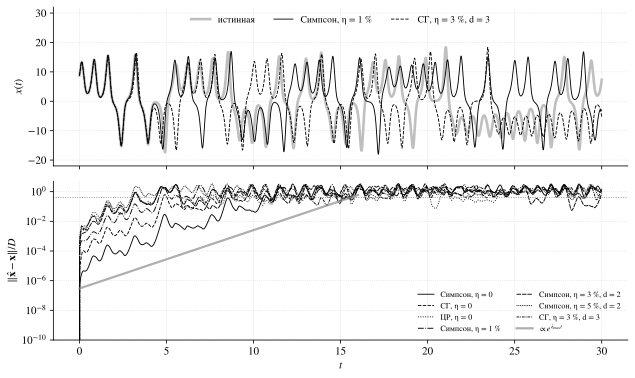

In [16]:
fig, ax = plt.subplots(2, 1, figsize=(9, 5.4), sharex=True)
ax[0].plot(t_te, X_te[:, 0], color="0.75", lw=2.6, label="истинная")
for label, ls in [("Симпсон, η = 1 %", "-"), ("СГ, η = 3 %, d = 3", "--")]:
    ax[0].plot(t_te, models[label]["X"][:, 0], "k", ls=ls, lw=0.9, label=label)
ax[0].set_ylim(-22, 32); ax[0].set_ylabel("$x(t)$"); ax[0].legend(ncol=3, loc="upper center")
for (label, m), ls in zip(models.items(), ["-", "--", ":", "-.", (0, (5, 1)), (0, (1, 1)), (0, (3, 1, 1, 1))]):
    e = np.linalg.norm(m["X"] - X_te, axis=1) / D
    ax[1].semilogy(t_te, e, "k", ls=ls, lw=0.9, label=label)
tt = np.linspace(0, 16, 2)
ax[1].semilogy(tt, 3e-7 * np.exp(LYAP * tt), color="0.55", lw=2.2, alpha=0.7, label="$\\propto e^{\\lambda_{\\max}t}$")
ax[1].axhline(0.4, color="0.5", ls=":", lw=0.9)
ax[1].set_ylim(1e-10, 5); ax[1].set_xlabel("$t$"); ax[1].set_ylabel("$\\|\\hat{\\mathbf{x}}-\\mathbf{x}\\|/D$")
ax[1].legend(ncol=2, fontsize=8, loc="lower right")
fig.tight_layout(); commas(fig); plt.show()

*Рис. Л6.* Прогноз тестовой траектории найденными моделями. Сверху — координата $x(t)$, снизу — относительная ошибка траектории в логарифмической шкале; горизонтальная линия — порог $0{,}4D$, серая прямая — рост с показателем Ляпунова. В первые доли единицы времени ошибка быстро поднимается от нуля до уровня, который задаёт неточность векторного поля, и дальше растёт экспоненциально.

**Главный результат шага.** У всех моделей ошибка растёт с одной и той же скоростью $e^{\lambda_{\max}t}$ — это свойство системы, а не метода. Качество модели определяет лишь **начальный уровень** ошибки. Поэтому горизонт прогноза растёт только логарифмически:
$$
T_{\mathrm v}\approx\frac1{\lambda_{\max}}\ln\frac{0{,}4D}{\delta_0},
$$
где $\delta_0$ — эффективная начальная ошибка, пропорциональная $\varepsilon_\Xi$. Уменьшение ошибки коэффициентов в 10 раз добавляет к горизонту лишь $\ln10/\lambda_{\max}\approx2{,}5$ единицы времени. Для инженера это принципиальный вывод: для хаотической системы бессмысленно требовать точного прогноза на большой срок — нужно требовать правильной **статистики** движения (шаг 7).

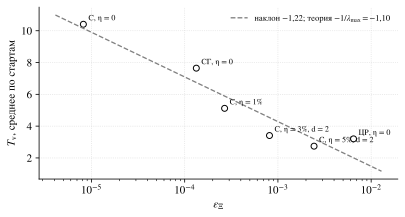

In [17]:
q = traj[traj["структура"]]
Tcol = "T_v, среднее по 15 стартам"
fig, ax = plt.subplots(figsize=(5.8, 3.2))
ax.semilogx(q["ε_Ξ"], q[Tcol], "ko", mfc="white", ms=6)
for lab, r in q.iterrows():
    ax.annotate(lab.replace("Симпсон", "С").replace(" %", "%"), (r["ε_Ξ"], r[Tcol]),
                textcoords="offset points", xytext=(5, 4), fontsize=8)
c = np.polyfit(np.log(q["ε_Ξ"]), q[Tcol], 1)
ee = np.logspace(np.log10(q["ε_Ξ"].min()) - 0.3, np.log10(q["ε_Ξ"].max()) + 0.3, 2)
ax.semilogx(ee, np.polyval(c, np.log(ee)), color="0.5", ls="--",
            label=f"наклон $-{-c[0]:.2f}$; теория $-1/\\lambda_{{\\max}}=-{1/LYAP:.2f}$".replace(".", "{,}"))
ax.set_xlabel("$\\varepsilon_\\Xi$"); ax.set_ylabel("$T_{\\mathrm{v}}$, среднее по стартам"); ax.legend(fontsize=8.5)
fig.tight_layout(); commas(fig); plt.show()

*Рис. Л7.* Горизонт достоверного прогноза в зависимости от ошибки коэффициентов (модели с верной структурой). Наклон прямой в полулогарифмических координатах близок к $-1/\lambda_{\max}$. Разброс точек вокруг прямой объясняется тем, что важна не только величина ошибки коэффициентов, но и её направление относительно неустойчивых направлений аттрактора.

Обратите внимание на модель «СГ, $\eta=3\%$, $d=3$» в таблице: её ошибка коэффициентов $\varepsilon_\Xi\approx0{,}2$, структура неверна, а горизонт прогноза не хуже, чем у модели с верной структурой и ошибкой $6\cdot10^{-3}$. Ошибка коэффициентов — не лучшая мера качества модели динамики. Важна ошибка **векторного поля** там, где проходит траектория: ложные члены могут иметь заметные коэффициенты, но малый вклад на аттракторе. Поэтому на рисунке показаны только модели с верной структурой.

## Шаг 7. Долгосрочная статистика: отображение Лоренца

Если точечный прогноз на большой срок невозможен, что тогда проверять? Лоренц сам предложил ответ: последовательные максимумы $z_n$ координаты $z$ связаны почти однозначной функцией $z_{n+1}=g(z_n)$ — **отображением Лоренца**. Оно характеризует аттрактор как целое и не зависит от начальной точки. Сравним отображения для истинной системы и для найденных моделей на длинном интервале (200 единиц времени).

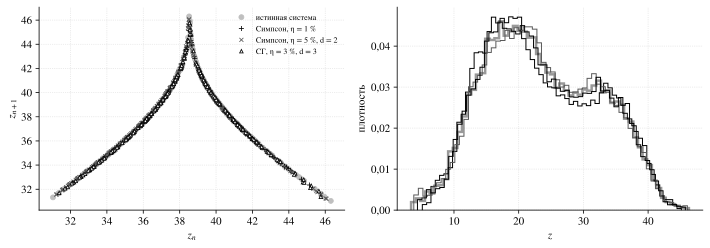

,максимумов,среднее z,СКО z
модель,,,
истинная система,266,23.578,8.602
"Симпсон, η = 1 %",264,23.477,8.704
"Симпсон, η = 5 %, d = 2",267,23.651,8.542
"СГ, η = 3 %, d = 3",266,23.592,8.591


In [18]:
long = {}
_, Xl = simulate(X_te[0], 200.0, transient=0.0); long["истинная система"] = Xl
for label in ["Симпсон, η = 1 %", "Симпсон, η = 5 %, d = 2", "СГ, η = 3 %, d = 3"]:
    _, Xl = simulate(X_te[0], 200.0, transient=0.0, f=model_rhs(models[label]["Xi"])); long[label] = Xl

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
mk = {"истинная система": ("o", "0.75", "0.75", 5), "Симпсон, η = 1 %": ("+", "black", "black", 5),
      "Симпсон, η = 5 %, d = 2": ("x", "0.35", "0.35", 4), "СГ, η = 3 %, d = 3": ("^", "white", "black", 3.5)}
rows = []
for label, Xl in long.items():
    if not np.all(np.isfinite(Xl)):
        rows.append({"модель": label, "максимумов": 0, "среднее z": np.nan, "СКО z": np.nan}); continue
    zn, zn1 = lorenz_map(Xl[:, 2])
    m_, fc, ec, ms = mk[label]
    ax[0].plot(zn, zn1, m_, ms=ms, mfc=fc, mec=ec, color=ec, mew=0.8, ls="none", label=label)
    ax[1].hist(Xl[:, 2], bins=60, density=True, histtype="step", color=ec if label != "истинная система" else "0.6",
               lw=2.5 if label == "истинная система" else 1.0, label=label)
    rows.append({"модель": label, "максимумов": zn.size, "среднее z": Xl[:, 2].mean(), "СКО z": Xl[:, 2].std()})
ax[0].set_xlabel("$z_n$"); ax[0].set_ylabel("$z_{n+1}$"); ax[0].legend(fontsize=8)
ax[1].set_xlabel("$z$"); ax[1].set_ylabel("плотность")
fig.tight_layout(); commas(fig); plt.show()
stats = pd.DataFrame(rows).set_index("модель"); display(stats.round(3))

*Рис. Л8.* Отображение Лоренца (слева) и распределение координаты $z$ (справа) на интервале 200 единиц времени.

Все три модели воспроизводят отображение и распределение почти неотличимо от истинной системы, хотя их траектории разошлись с истинной уже через несколько единиц времени. Это относится и к модели с ложными членами (СГ, $\eta=3\%$, $d=3$): на аттракторе, где её подбирали, ложные члены почти ничего не вносят.

Но это не гарантия. Ложные кубические члены малы на аттракторе и велики вдали от него. Если траекторию модели запустить из точки вне аттрактора или если её что-то выбьет туда, такая модель может притянуться к другому режиму или уйти на бесконечность. Это экстраполяция в смысле п. 3.1.1, только в пространстве состояний. Проверьте это в задании 6. Вопрос о том, где именно данные определяют модель, — центральный в блокноте главы 4.

**Инженерный критерий приёмки** модели хаотической системы, таким образом, двухуровневый: точный прогноз на горизонте нескольких времён Ляпунова и правильная статистика (отображение, распределения, спектр) на больших временах.

## Шаг 8. Где кончаются возможности библиотеки

SINDy работает блестяще, пока истинные правые части **лежат в библиотеке**. Что если инженер ошибся в выборе функций? Представим «электронный» вариант системы, в котором линейный усилитель первого уравнения заменён насыщающимся каскадом:
$$
\dot x=\sigma\tanh(y-x). \tag{Л.4}
$$
Функции $\tanh$ в полиномиальной библиотеке нет. МНК подберёт какое-то полиномиальное приближение, но точной структуры не найдёт; добавлять в библиотеку всё подряд нельзя — шаг 5 показал цену лишней свободы.

Этот вопрос — переход к главе 4. Сеть Колмогорова–Арнольда не требует заранее выбирать функции: она обучает одномерные функции на рёбрах и позволяет «прочитать» их форму после обучения. В блокноте главы 4 задание с (Л.4) решается именно так.

## Задания

1. **Шаг дискретизации.** Повторите шаг 4в для $\Delta t=0{,}02$ и $0{,}05$ (прореживая запись). Как меняется преимущество формулы Симпсона над формулой трапеций? Объясните через порядок остатка квадратурных формул.
2. **Длина записи.** Для $\eta=3\%$ и библиотеки $d=3$ найдите, при какой длине обучающей записи (в единицах времени Ляпунова) структура восстанавливается в 5 из 5 реализаций. Почему длинная запись не устраняет смещение из п. 3 вывода шага 5?
3. **Выбор порога по валидации.** Предложите автоматическое правило выбора $\tau$ по фронту Парето (рис. Л3) и проверьте его для $\eta=0{,}5\%$, $1\%$ и $2\%$.
4. **Другие параметры.** Восстановите систему при $\rho=14$ (устойчивые фокусы вместо хаоса). Почему по одной траектории, сходящейся к точке равновесия, коэффициенты определяются хуже? Свяжите ответ с обусловленностью матрицы $\Theta$.
5. **Ошибка в библиотеке.** Сгенерируйте данные по системе с (Л.4) и попробуйте восстановить её полиномиальной библиотекой $d=3$ и $d=5$. Сравните валидационную ошибку, время достоверного прогноза и отображение Лоренца.
6. **Модель вне аттрактора.** Проинтегрируйте модели «Симпсон, $\eta=1\%$» и «СГ, $\eta=3\%$, $d=3$» из начальных точек `box_points(20)`, лежащих далеко от аттрактора. Какая из моделей сохраняет поведение истинной системы и почему?

## Связи с другими главами

| Идея | Глава |
|---|---|
| Фиксированный базис, МНК, квадратуры | 3 (основной текст) |
| Обучаемые одномерные функции вместо библиотеки; какие данные нужны гибкой модели | 4, `KAN_Lorenz_attarctor.ipynb` |
| Слабая (интегральная) форма уравнений, вариационные принципы | 5 |
| Некорректность дифференцирования, переобучение на лишних членах, регуляризация | 6 |
| Прогноз временных рядов без знания уравнений (LSTM, GRU) | 7–8 |
| Показатели Ляпунова, устойчивость, аттракторы | 10 |
| Обратная задача: параметры $\sigma,\rho,\beta$ с помощью PINN | 11 |